# MSIT EEG Pipeline - Scientific Programming Project

Pipeline for the Nencki-Symfonia dataset, MSIT task: predicting single-trial reaction time from EEG data
**Steps:** 
1. Setup
2. Download metadata
3. Participant demographics
4. Exploratory data analysis + computing RTs
5. Downloading raw EEG
6. Preprocessing functions
7. Loading the first subject
13. Walkthrough on sub-01: raw EEG, band-pass filter, comparison, trimming, downsampling, comparison (+ save)
14. Preprocess all subjects
15. ICA (blink removal)
16. Epoching
17. Wavelet transform
18. Channel selection
19. Feature extraction

## 1. Setup

In [ ]:
!pip install s3fs mne pandas requests matplotlib nemar scikit-learn

ERROR: Could not find a version that satisfies the requirement nemar (from versions: none)
ERROR: No matching distribution found for nemar


In [ ]:
!pip install -q nemar-py #library necessary to get the dataset, easiest way to access it

Creating folder strucutre

In [ ]:
#folders for each of the stages, we re-use each in the next stage. 
DS_DIR    = Path("data/downsampled")      #250Hz eeg data
ICA_DIR   = Path("data/ica_cleaned")      #removed blinks
EPO_DIR   = Path("data/epochs")           #splitting into the individual trials
SCORE_DIR = Path("data/channel_scores")   #scoring the channels to select best on
FEAT_DIR  = Path("data/features")         #final features
FIG_DIR   = Path("output")                #all outputs

#creating all the necessary directories
for d in [DS_DIR, ICA_DIR, EPO_DIR, SCORE_DIR, FEAT_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

## 2. Download dataset metadata
Pulls the metadata GitHub (events/participants files, not the raw EEG binaries)

In [2]:
import requests, tarfile, io, glob, re

# Getting the metadata from the github
URL = "https://codeload.github.com/OpenNeuroDatasets/ds004621/tar.gz/refs/heads/main"
META_DIR = "ds004621-main"

r = requests.get(URL)
tarfile.open(fileobj=io.BytesIO(r.content)).extractall(".")

## 3. Participant demographics

In [3]:
import pandas as pd

#Loading participant data
df = pd.read_csv(
    f"{META_DIR}/participants.tsv",
    sep="\t"
) 

age_ranges = pd.cut(
    df["age"],
    bins=[0, 20, 23, 26, 30, 100],
    labels=["18–20", "21–23", "24–26", "27–30", "31+"]
)

demographics = pd.DataFrame({
    "Count": age_ranges.value_counts().sort_index()
})

characteristics = pd.DataFrame({
    "Mean": [
        df["stress"].mean(),
        df["rest"].mean()
    ],
    "SD": [
        df["stress"].std(),
        df["rest"].std()
    ]
}, index=["Stress (1–5)", "Rest (1–5)"])

print("Age")
display(demographics)

print("Gender")
display(df["sex"].value_counts().to_frame("Count"))

print("Stress and Rest")
display(characteristics.round(2))

print("Caffeine use")
display(df["caffeine uptake"].value_counts().to_frame("Count"))

print("Medication use")
display(df["medication use"].value_counts().to_frame("Count"))

Age


,Count
age,
18–20,5
21–23,15
24–26,12
27–30,4
31+,6


Gender


,Count
sex,
F,22
M,20


Stress and Rest


,Mean,SD
Stress (1–5),2.76,1.08
Rest (1–5),3.45,0.99


Caffeine use


,Count
caffeine uptake,
0,25
1,17


Medication use


,Count
medication use,
0,37
1,5


## 4. Computing Reaction Times for all

In [5]:
from pathlib import Path

# Codes for different conditions from each task.
CONDITION_MAP = {
    "srt": None,  # only one condition
    #00 is no conflict, F0 is flanker conflict, S0 is simon conflict, FS is flanker-simon conflict
    "msit": {"S  5": "F0", "S  6": "FS", "S  7": "00", "S  8": "S0"}, 
    "oddball": {"S  6": "target", "S  7": "distractor"},
}

#computing reaction time, is first response after the stimulus, within 2 s.
def get_reactiontimes(sub, task, cond_map, max_rt=2.0):
    path = f"{META_DIR}/{sub}/eeg/{sub}_task-{task}_events.tsv"
    df = pd.read_csv(path, sep="\t")
    df["event_type"] = df["event_type"].str.strip()

    rows = []
    for i in df.index[df["trial_type"] == "stimulus"]:
        code = df.loc[i, "event_type"]
        if cond_map is not None and code not in cond_map:
            continue  # skip conditions we're not measuring (e.g. "standard")
        condition = cond_map[code] if cond_map else "SRT"

        next_rows = df.loc[i + 1: i + 2]
        resp = next_rows[next_rows["trial_type"] == "response"]
        if resp.empty:
            continue

        rt = resp.iloc[0]["onset"] - df.loc[i, "onset"]
        if 0 < rt <= max_rt:
            rows.append({"subject": sub, "condition": condition, "rt_ms": rt * 1000})
    return rows

# Run across all subjects, for each task
subjects = sorted(set(
    re.search(r"(sub-\d+)", p.name).group(1)
    for p in Path(META_DIR).glob("sub-*/eeg/*_task-srt_events.tsv")
))

print(f"Found {len(subjects)} subjects.")

# the average reaction times for all the different conditions within the dataset, using the metadata.
for task, cond_map in CONDITION_MAP.items():
    all_rts = []
    for sub in subjects:
        try:
            all_rts += get_reactiontimes(sub, task, cond_map)
        except FileNotFoundError:
            continue

    rt_df = pd.DataFrame(all_rts)
    print(f"\n{task.upper()}")
    print(rt_df.groupby("condition")["rt_ms"].agg(["count", "mean", "std", "median"]).round(1))

    rt_df.to_csv(f"{task}_rt.csv", index=False)

Found 41 subjects.

SRT
           count   mean    std  median
condition                             
SRT         5231  309.2  211.3   269.0

MSIT
           count   mean    std  median
condition                             
00          4118  536.0  119.6   521.0
F0          3777  672.4  145.6   649.0
FS          3943  741.0  174.9   717.0
S0          4275  590.0  124.6   571.0

ODDBALL
            count   mean    std  median
condition                              
distractor    512  517.4  212.3   459.5
target       3174  534.9  122.3   519.0


### Trials per subject for MSIT Task

Here we select fro only the MSIT task as that will be teh focus 

In [6]:
df = pd.read_csv("msit_rt.csv")  # columns: subject, condition, rt_ms

print("Total trials per subject")
print(df.groupby("subject").size().describe())

print("\nTrials per subject, per condition")
print(df.groupby(["subject", "condition"]).size().unstack())

Total trials per subject
count     41.00000
mean     393.00000
std       20.87223
min      302.00000
25%      390.00000
50%      396.00000
75%      403.00000
max      438.00000
dtype: float64

Trials per subject, per condition
condition   00   F0   FS   S0
subject                      
sub-01      99   99  101  106
sub-02     107   88   97  104
sub-03     101  111   99   91
sub-04     102   86  100  115
sub-05     107   96   92  109
sub-06      89  100   91  111
sub-07      93   66   68  101
sub-08      99   98  103  102
sub-09      97  105   83   99
sub-10      87   90   91  105
sub-11      96  105   90  110
sub-12     101   83  117   91
sub-13     110   86   99   99
sub-14      92   82  112  111
sub-15     100  102   81  103
sub-16      92   92   84  107
sub-17     109   86   86  107
sub-18     100   90  110   95
sub-19      91   91  114   98
sub-20     100   87  105  105
sub-21      79   67   86   70
sub-22     102   83  110   99
sub-23     109   97  114  118
sub-24      98   88   9

## 5. Download full raw EEG data
Pulls the actual EEG binaries (`.eeg`/`.vhdr`/`.vmrk`) via NEMAR, per subject, MSIT task only.

In [8]:
import os
import nemar

#downloads the 42 subjects raw EEG data
DATA_DIR = os.path.join(os.getcwd(), "data", "on004621")
os.makedirs(DATA_DIR, exist_ok=True)

for i in range(1, 43):
    nemar.download(
        dataset="on004621",
        target_dir=DATA_DIR,
        subject=[f"{i:02d}"],
        task="msit",
        datatype="eeg",
    )

c:\Users\krutv\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


This is nemar-py 0.3.3.
Preparing to download on004621 from https://data.nemar.org/
Retrieving 18 of 1312 manifest files (16 concurrent downloads).
All selected files already exist locally.
Finished downloading on004621 v1.0.0.
This is nemar-py 0.3.3.
Preparing to download on004621 from https://data.nemar.org/
Retrieving 18 of 1312 manifest files (16 concurrent downloads).
All selected files already exist locally.
Finished downloading on004621 v1.0.0.
This is nemar-py 0.3.3.
Preparing to download on004621 from https://data.nemar.org/
Retrieving 18 of 1312 manifest files (16 concurrent downloads).
All selected files already exist locally.
Finished downloading on004621 v1.0.0.
This is nemar-py 0.3.3.
Preparing to download on004621 from https://data.nemar.org/
Retrieving 18 of 1312 manifest files (16 concurrent downloads).
All selected files already exist locally.
Finished downloading on004621 v1.0.0.
This is nemar-py 0.3.3.
Preparing to download on004621 from https://data.nemar.org/
Retr

## 6. Essential Pre-Processing Functions

Here we define eeg_paths, which will return the .vhdr and .tsv files for a subject when called upon. 

bandpass() applies a band-pass filter 0.1-30Hz.
crop_to_task() trims the dead times of each raw EEG data.
downsample() reduces the sampling rate from 1000Hz to 250Hz.

In [ ]:
import mne
import pandas as pd
from pathlib import Path


DATASET = "on004621"
DATA_ROOT = Path("data") / DATASET

# Get the .vhdr and .tsv file paths for a subject
def eeg_paths(subject):
    folder = DATA_ROOT / subject / "eeg"
    vhdr_file = folder / f"{subject}_task-msit_eeg.vhdr"
    events_file = folder / f"{subject}_task-msit_events.tsv"

    return vhdr_file, events_file

#applies bandpass filter
def bandpass(raw, l_freq=0.1, h_freq=30.0, copy=True):
    raw = raw.copy() if copy else raw
    return raw.filter(l_freq=l_freq, h_freq=h_freq, fir_design="firwin")

#trims the dead times of each EEG data
def crop_to_task(raw, events, buffer_sec=1.0, copy=True):
    raw = raw.copy() if copy else raw
    task_events = events[events["trial_type"].isin(["stimulus", "response"])]
    tmin = max(0, task_events["onset"].min() - buffer_sec)
    tmax = min(raw.times[-1], task_events["onset"].max() + buffer_sec)
    raw_cropped = raw.crop(tmin=tmin, tmax=tmax)

    return raw_cropped

#downsampels the raw data to 250Hz from 1000Hz reducing the size
def downsample(raw, sfreq=250, copy=True):
    raw = raw.copy() if copy else raw
    return raw.resample(sfreq)

## 7. Loading the first subject

Here we load the first subject once, to use as our visualization for first parts of pre-processsing

In [10]:
SUBJECT = "sub-01"
vhdr_path, events_path = eeg_paths(SUBJECT) #returns the paths, of eeg data and the events

#reading the raw eeg data from the vhdr file
raw_orig = mne.io.read_raw_brainvision(vhdr_path, preload=True)
events = pd.read_csv(events_path, sep="\t")
print("Loaded 1st subject")

Extracting parameters from data\on004621\sub-01\eeg\sub-01_task-msit_eeg.vhdr...
Setting channel info structure...
Reading 0 ... 1437859  =      0.000 ...  1437.859 secs...
Loaded 1st subject


## 8. Visualize raw EEG

Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


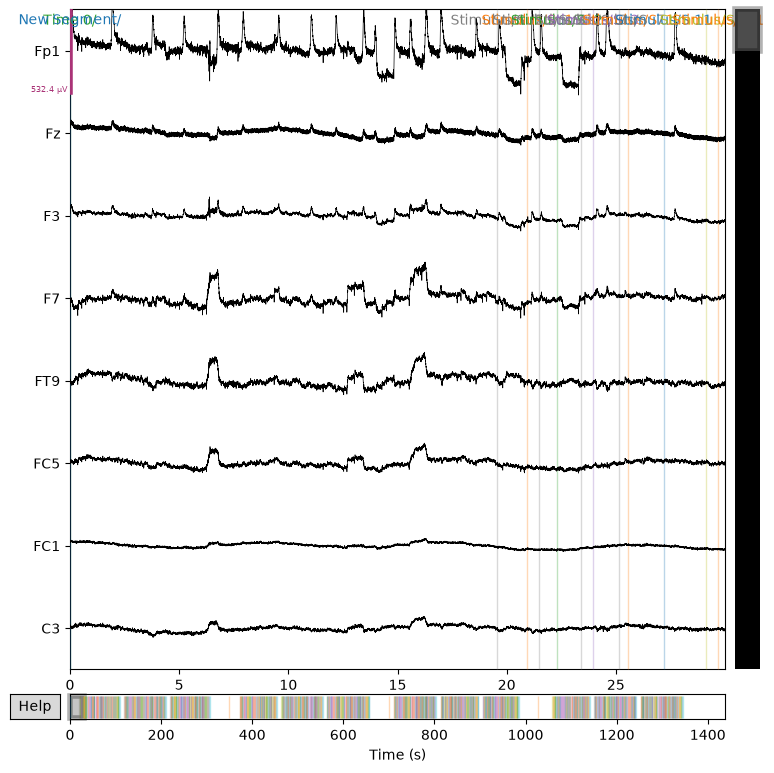

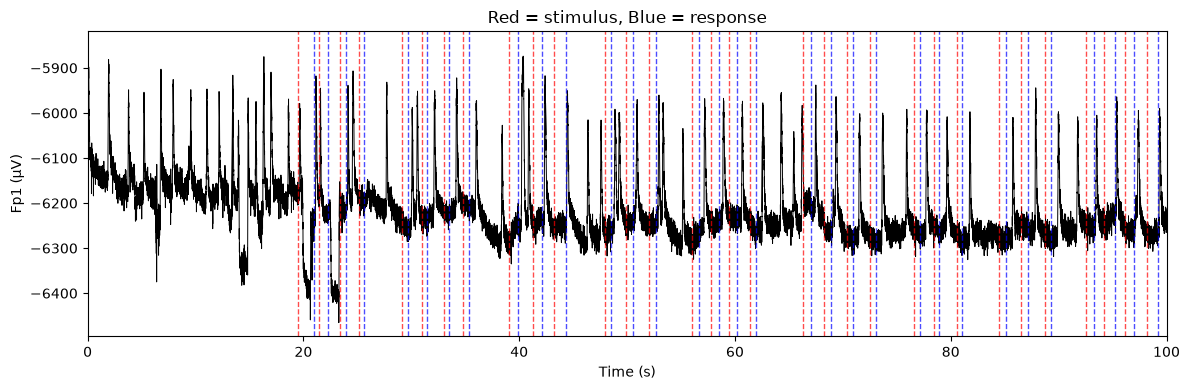

In [11]:
import matplotlib.pyplot as plt


# Raw input plot for first 10 s of 20 of the channels
raw_orig.plot(duration=30, n_channels=8, scalings="auto")

# overlay of the stimulus and response on 1 channel
T_WINDOW = 100  # seconds shown
channels_to_plot = raw_orig.ch_names[:8]          # first 8 channels

data, times = raw_orig.get_data(
    picks=[channels_to_plot[0]],
    return_times=True
)

events_df = pd.read_csv(events_path, sep="\t")
events_in_window = events_df[events_df["onset"] <= T_WINDOW] #keeping the events within time window

fig, ax = plt.subplots(figsize=(12, 4))

# EEG trace
window = times <= T_WINDOW
ax.plot(
    times[window],
    data[0][window] * 1e6,
    linewidth=0.7,
    color="black"
)

# Event markers for the stimulus and reaction onset
for _, ev in events_in_window.iterrows():
    if ev["trial_type"] == "stimulus":
        color = "red"
    elif ev["trial_type"] == "response":
        color = "blue"
    else:
        continue

    ax.axvline(
        ev["onset"],
        color=color,
        linestyle="--",
        alpha=0.7,
        linewidth=1
    )

ax.set_xlim(0, T_WINDOW)
ax.set_xlabel("Time (s)")
ax.set_ylabel(f"{channels_to_plot[0]} (µV)")
ax.set_title("Red = stimulus, Blue = response")

plt.tight_layout()
plt.savefig(f"output/{SUBJECT}_events_overlay.png", dpi=150)
plt.show()

## 9. Apply band-pass filter (0.1,30Hz)

We filter on the entire recording, before the edge trimming, so the filter’s edge artifacts are in the cropped-away dead time and can be removed.

We use 0.1Hz to remove drift. 30Hz for muscle and line noise.

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 33001 samples (33.001 s)

Effective window size : 2.048 (s)
Plotting power spectral density (dB=True).


C:\Users\krutv\AppData\Local\Temp\ipykernel_16580\2885793373.py:5: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw_orig.compute_psd(fmax=60).plot(axes=axes[0], show=False)


Effective window size : 2.048 (s)
Plotting power spectral density (dB=True).


C:\Users\krutv\AppData\Local\Temp\ipykernel_16580\2885793373.py:7: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw_filt.compute_psd(fmax=60).plot(axes=axes[1], show=False)


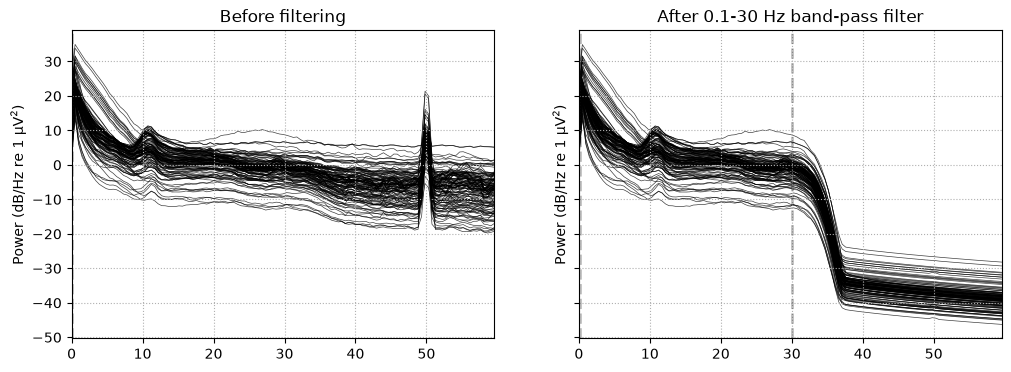

In [12]:
raw_filt = bandpass(raw_orig) #calling the bandpass filter on the orginal raw data

# Before/after comparison plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
raw_orig.compute_psd(fmax=60).plot(axes=axes[0], show=False)
axes[0].set_title("Before filtering")
raw_filt.compute_psd(fmax=60).plot(axes=axes[1], show=False)
axes[1].set_title("After 0.1-30 Hz band-pass filter")
plt.savefig(f"output/{SUBJECT}_filter_before_after.png", dpi=150)
plt.show()

## 10. Compare one channel before vs. after filtering

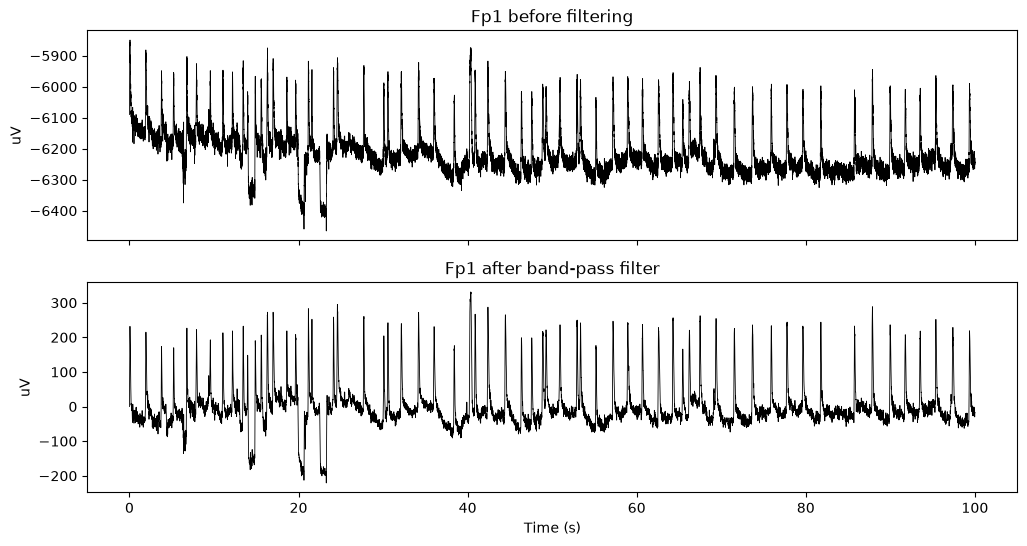

In [13]:
CHANNEL = "Fp1"

data_before, times = raw_orig.get_data(picks=[CHANNEL], return_times=True)
data_after, _ = raw_filt.get_data(picks=[CHANNEL], return_times=True)
window = times <= 100   # first 100 seconds

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=False)
# sharey=False: the unfiltered signal sits on a large DC offset (thousands of uV,
# from the electrode itself, not the brain) - sharing the y-axis would squash the filtered panel.

axes[0].plot(times[window], data_before[0][window] * 1e6, linewidth=0.6, color="black")
axes[0].set_title("Fp1 before filtering")
axes[0].set_ylabel("uV")

axes[1].plot(times[window], data_after[0][window] * 1e6, linewidth=0.6, color="black")
axes[1].set_title("Fp1 after band-pass filter")
axes[1].set_ylabel("uV")
axes[1].set_xlabel("Time (s)")

plt.savefig(f"output/{SUBJECT}_{CHANNEL}_before_after_filter.png", dpi=150)
plt.show()

## 11 Trimming the dead times of the EEG after filtering

Here we use mne to remove the eeg data from before the first event, and after the last event. 

Overwriting existing file.
Writing c:\Users\krutv\Downloads\reaction_time_project\trimmed_eeg\sub-01_cropped_raw.fif
Overwriting existing file.
Closing c:\Users\krutv\Downloads\reaction_time_project\trimmed_eeg\sub-01_cropped_raw.fif
[done]


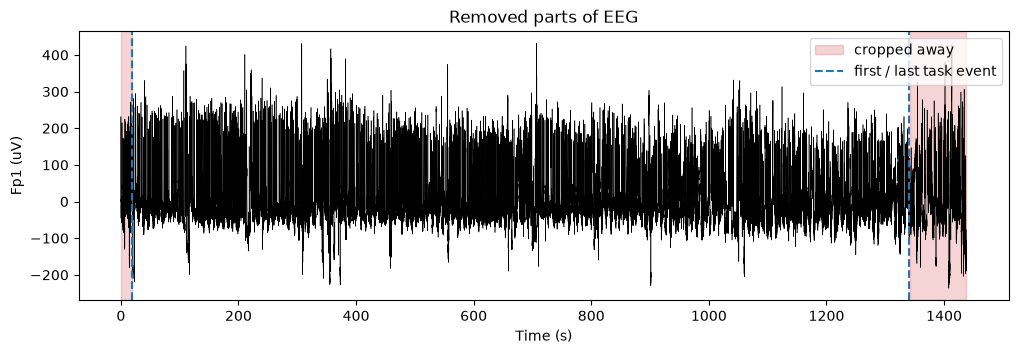

In [14]:
raw_crop = crop_to_task(raw_filt, events)

tmin = raw_crop.first_time     # where the crop starts on the orginal time
tmax = tmin + raw_crop.times[-1]

#trimming the data
data, times = raw_filt.get_data(picks=["Fp1"], return_times=True)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(times[::10], data[0][::10] * 1e6, linewidth=0.4, color="black")
ax.axvspan(0, tmin, color="tab:red", alpha=0.2, label="cropped away")
ax.axvspan(tmax, times[-1], color="tab:red", alpha=0.2)
for t in events.loc[events["trial_type"].isin(["stimulus", "response"]), "onset"].iloc[[0, -1]]:
    ax.axvline(t, color="tab:blue", linestyle="--", label="first / last task event")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Fp1 (uV)")
ax.set_title("Removed parts of EEG")
handles, labels = ax.get_legend_handles_labels()
ax.legend(dict(zip(labels, handles)).values(), dict(zip(labels, handles)).keys())
plt.savefig(f"output/{SUBJECT}_crop_window.png", dpi=150)
plt.show()

## 12. Downsampling

Here we downsample from 1000Hz to 250Hz, since the information at 1000Hz is not necessarily required for processing in order to use in the model. And reduces the data usage of each sample by a significant amount. 

Do after filtering, so nothing above 125 Hz can fold back in. 

In [15]:
raw_250 = downsample(raw_crop)

print(f"Before: {raw_crop.info['sfreq']:.0f} Hz, {raw_crop.n_times} samples")
print(f"After:  {raw_250.info['sfreq']:.0f} Hz, {raw_250.n_times} samples")

Before: 1000 Hz, 1323633 samples
After:  250 Hz, 330908 samples


## 13. Compare 1000 Hz vs. 250 Hz

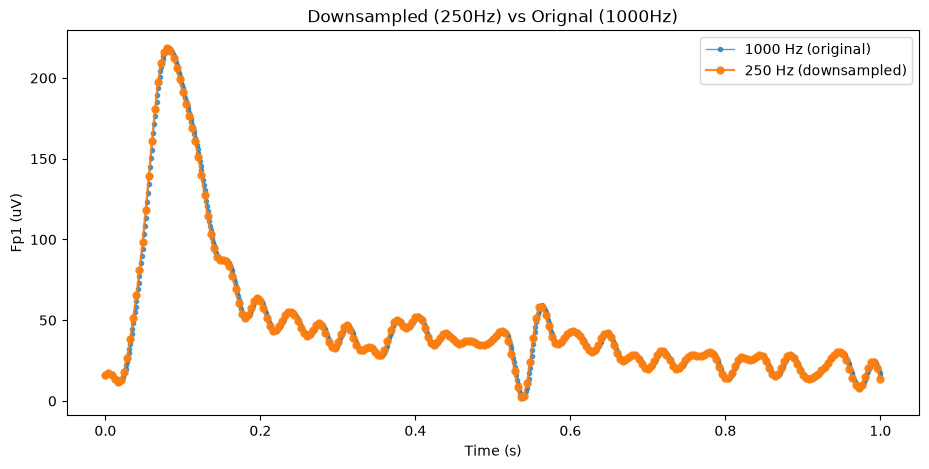

In [16]:
CHANNEL = "Fp1"

# get the data and times for the trimmed data and downsampled data
data_1000, times_1000 = raw_crop.get_data(picks=[CHANNEL], return_times=True)
data_250, times_250 = raw_250.get_data(picks=[CHANNEL], return_times=True)

# Short time window to see the individual points
t_start, t_end = 0, 1
mask_1000 = (times_1000 >= t_start) & (times_1000 <= t_end)
mask_250 = (times_250 >= t_start) & (times_250 <= t_end)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(times_1000[mask_1000], data_1000[0][mask_1000] * 1e6,
        "o-", markersize=3, linewidth=1, label="1000 Hz (original)", alpha=0.7)
ax.plot(times_250[mask_250], data_250[0][mask_250] * 1e6,
        "o-", markersize=5, linewidth=1.5, label="250 Hz (downsampled)", alpha=0.9)
ax.set_xlabel("Time (s)")
ax.set_ylabel(f"{CHANNEL} (uV)")
ax.set_title("Downsampled (250Hz) vs Orignal (1000Hz)")
ax.legend()
plt.savefig(f"output/{SUBJECT}_{CHANNEL}_resample_comparison.png", dpi=150)
plt.show()

Here we check the correlation between orignal sample and the downsampled data to check if it still matches, and we didnt lose lots of information. 

In [17]:
import numpy as np
from scipy.stats import pearsonr

ch = "Pz" #picking a channel to check
x1000 = raw_crop.copy().pick(ch).get_data()[0]
x250  = raw_250.copy().pick(ch).get_data()[0]

x1000_every4 = x1000[::4][:len(x250)] # 1000 Hz samples at the same time points
x250 = x250[:len(x1000_every4)]

#pearson correlaton and rmse metrics
r, p = pearsonr(x1000_every4, x250)
rmse = np.sqrt(np.mean((x1000_every4 - x250) ** 2)) * 1e6
print(f"correlation r = {r:.5f}, RMSE = {rmse:.3f}")

correlation r = 0.99945, RMSE = 0.620


### Save the results

We save the downsampled data, so it can later be recalled quickly for ICA and further steps.

In [18]:
out_path = f"data/downsampled/{SUBJECT}_250hz_raw.fif"
raw_250.save(out_path, overwrite=True)
print(f"Saved to {out_path}")

Overwriting existing file.
Writing c:\Users\krutv\Downloads\reaction_time_project\data\downsampled\sub-01_250hz_raw.fif
Overwriting existing file.
Closing c:\Users\krutv\Downloads\reaction_time_project\data\downsampled\sub-01_250hz_raw.fif
[done]
Saved to data/downsampled/sub-01_250hz_raw.fif


## 14. Preprocess all subjects


In [ ]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

MONTAGE  = "colin27_1005" #for mne library 
SUBJECTS = [f"sub-{i:02d}" for i in range(1, 43)]

#Here we define a parallel computing approach
from joblib import Parallel, delayed

N_JOBS = 3   # lower it if you run out of memory
#runs side by side, doesnt stop if one subject fails
def run_parallel(fn, subjects, n_jobs=N_JOBS):
    def safe(s):
        try:
            return fn(s)
        except Exception as e:
            return f"{s}: FAILED -- {e}"
    out = Parallel(n_jobs=n_jobs)(delayed(safe)(s) for s in subjects)
    for o in out:
        if isinstance(o, str) and "FAILED" in o:
            print(o)
    return out

In [20]:
#filter > crop > downsample > save
def preprocess_subject(subject, overwrite=False):
    out_path = DS_DIR / f"{subject}_250hz_raw.fif"
    if out_path.exists() and not overwrite:
        print(f"{subject}: already done, skipping")
        return out_path

    vhdr_path, events_path = eeg_paths(subject)
    raw = mne.io.read_raw_brainvision(vhdr_path, preload=True, verbose=False)
    events = pd.read_csv(events_path, sep="\t")

    #using our pre-written functions
    raw = bandpass(raw, copy=False)
    raw = crop_to_task(raw, events, copy=False)
    raw = downsample(raw, copy=False)
    raw.save(out_path, overwrite=True)
    
    print(f"{subject}: saved {out_path.name}")
    return out_path

run_parallel(preprocess_subject, SUBJECTS, n_jobs=2)

[WindowsPath('data/downsampled/sub-01_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-02_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-03_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-04_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-05_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-06_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-07_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-08_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-09_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-10_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-11_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-12_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-13_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-14_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-15_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-16_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-17_250hz_raw.fif'),
 WindowsPath('data/downsampled/sub-18_250hz_raw.fif'),
 WindowsPa

## 15. Independent Component Analysis (ICA)
This removes the eye blinks seen in the data. ICA splits the data into 20 independent sources. the blink source is found using Fp1 as a stand-in EOG channel, and removed.

- ICA is fitted on a 1 Hz high-passed copy (slow drift stops it converging) with `decim=3` (faster), and then applied to the normal 0.1-30 Hz data.
- Channels without a known position (`TP9 LEFT EAR`, `TP10 RIGHT EAR`, `O9`, `O10`) are dropped
- `n_components` must is around 20: with fewer, MNE's blink detector cannot fire.

In [21]:
#function fits the ICA to a 1Hz copy. Split the 128 channels into 20 sources
def fit_ica(raw, n_components=20):
    raw = raw.copy()
    raw.set_montage(MONTAGE, on_missing="ignore", verbose=False)

    #channels with no posisiton are dropped, cant use for the mapping
    no_pos = [ch["ch_name"] for ch in raw.info["chs"]
              if np.isnan(ch["loc"][:3]).any() or np.allclose(ch["loc"][:3], 0)]
    raw.drop_channels(no_pos)

    #fitting to 1Hz copy to stop convergence
    raw_for_fit = raw.copy().filter(l_freq=1.0, h_freq=None, verbose=False)
    ica = mne.preprocessing.ICA(n_components=n_components, rng=42, max_iter="auto")
    ica.fit(raw_for_fit, decim=3, verbose=False)

    eog_idx, scores = ica.find_bads_eog(raw, ch_name="Fp1", verbose=False)
    ica.exclude = list(eog_idx)
    if not eog_idx:
        print("no blink detected")
    return raw, ica, scores

#remove the excluded components from the data
def apply_ica(raw, ica, copy=True):
    raw = raw.copy() if copy else raw
    return ica.apply(raw, verbose=False)

#creating a baseline FCz channel to re-refernce the channels to average. 
def rereference(raw):
    if "FCz" not in raw.ch_names:
        raw = mne.add_reference_channels(raw, ref_channels="FCz")
        raw.set_montage(MONTAGE, on_missing="ignore", verbose=False)
    raw.set_eeg_reference("average", projection=False, verbose=False)
    return raw

### Running on 1 Particpants

In [22]:
SUBJECT = "sub-01"
raw_ds = mne.io.read_raw_fif(DS_DIR / f"{SUBJECT}_250hz_raw.fif", preload=True)

raw_pos, ica, eog_scores = fit_ica(raw_ds)
print(f"Blink component(s) detected: {ica.exclude}")

# All component topographies, the blink-detection scores, and the blink component(s) in detail
ica.plot_components(show=False).savefig(FIG_DIR / f"{SUBJECT}_ica_components.png", dpi=150)

Opening raw data file data\downsampled\sub-01_250hz_raw.fif...
Isotrak not found
    Range : 4634 ... 335541 =     18.536 ...  1342.164 secs
Ready.
Reading 0 ... 330907  =      0.000 ...  1323.628 secs...
Blink component(s) detected: [np.int64(0)]


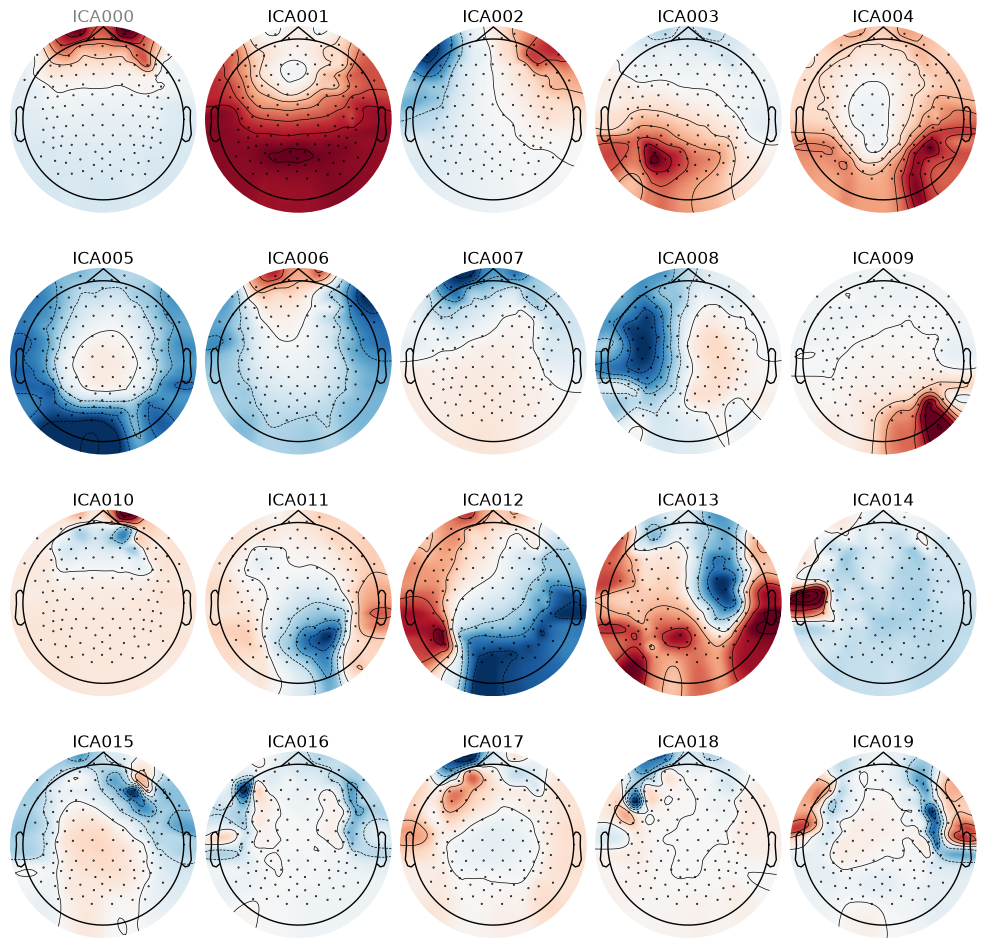

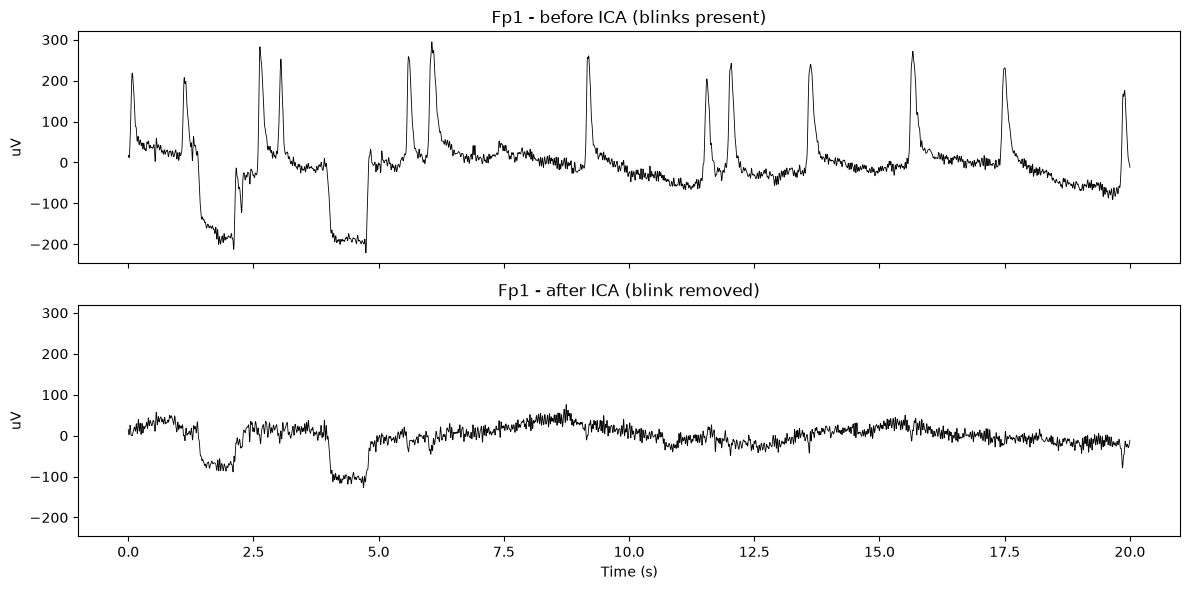

C:\Users\krutv\AppData\Local\Temp\ipykernel_16580\505655715.py:30: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  raw = mne.add_reference_channels(raw, ref_channels="FCz")


Overwriting existing file.
Writing c:\Users\krutv\Downloads\reaction_time_project\data\ica_cleaned\sub-01_ica_raw.fif
Overwriting existing file.
Closing c:\Users\krutv\Downloads\reaction_time_project\data\ica_cleaned\sub-01_ica_raw.fif
[done]


[WindowsPath('c:/Users/krutv/Downloads/reaction_time_project/data/ica_cleaned/sub-01_ica_raw.fif')]

In [23]:
raw_clean = apply_ica(raw_pos, ica)       # same reference before and after, so the comparison shows only the ICA effect

# Before/after comparison on Fp1
data_before, times = raw_pos.get_data(picks=["Fp1"], return_times=True)
data_after, _ = raw_clean.get_data(picks=["Fp1"], return_times=True)
window = times <= 20

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
axes[0].plot(times[window], data_before[0][window] * 1e6, linewidth=0.6, color="black")
axes[0].set_title("Fp1 - before ICA (blinks present)")
axes[0].set_ylabel("uV")
axes[1].plot(times[window], data_after[0][window] * 1e6, linewidth=0.6, color="black")
axes[1].set_title("Fp1 - after ICA (blink removed)")
axes[1].set_ylabel("uV")
axes[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.savefig(FIG_DIR / f"{SUBJECT}_ica_before_after.png", dpi=150)
plt.show()

# Save the cleaned data
raw_clean = rereference(raw_clean)
ica_path = ICA_DIR / f"{SUBJECT}_ica_raw.fif"
raw_clean.save(ica_path, overwrite=True)

### ICA for all the subjects

In [24]:
def clean_subject(subject, overwrite=False):
    out_path = ICA_DIR / f"{subject}_ica_raw.fif"
    if out_path.exists() and not overwrite:
        print(f"{subject}: already done, skipping")
        return out_path
    raw = mne.io.read_raw_fif(DS_DIR / f"{subject}_250hz_raw.fif", preload=True, verbose=False)
    raw_pos, ica, _ = fit_ica(raw)
    raw_clean = rereference(apply_ica(raw_pos, ica, copy=False))
    raw_clean.save(out_path, overwrite=True)
    print(f"{subject}: blink component(s) {ica.exclude} removed, saved {out_path.name}")
    return out_path

run_parallel(clean_subject, SUBJECTS, n_jobs=2)

[WindowsPath('data/ica_cleaned/sub-01_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-02_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-03_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-04_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-05_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-06_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-07_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-08_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-09_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-10_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-11_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-12_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-13_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-14_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-15_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-16_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-17_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-18_ica_raw.fif'),
 WindowsPath('data/ica_cleaned/sub-19_ica_raw.

## 16. Epoching
We split each recording into its individual trials, as each recording has over 400 trials. So each trial can have its own reaction time and features, whcih can later be used for the model. Stimuli are at least 1.73 s apart, so window: -0.8 to +1.2s around the stimulus. Enough room for the wavelet baseline, room for the slowest responses.

In [25]:
MSIT_CODES = CONDITION_MAP["msit"] #pre-defined in section 4 when doing visualizing
EVENT_ID   = {"00": 1, "S0": 2, "F0": 3, "FS": 4}
CONDITIONS = list(EVENT_ID)
EPOCH_TMIN, EPOCH_TMAX = -0.8, 1.2  # seconds around the stimulus

# function to keep the epochs matched with the stimulus, response so the reaction times mathc.
def stimulus_table(events_path, max_rt=2.0):
    df_ev = pd.read_csv(events_path, sep="\t")
    df_ev["event_type"] = df_ev["event_type"].str.strip()
    stim = df_ev[df_ev["event_type"].isin(MSIT_CODES)]
    stim_t = stim["onset"].to_numpy()
    resp_t = df_ev.loc[df_ev["trial_type"] == "response", "onset"].to_numpy()
    rows = []
    for k, (s, code_) in enumerate(zip(stim_t, stim["event_type"])):
        j = np.searchsorted(resp_t, s, side="right")        # first response after this stimulus
        next_stim = stim_t[k + 1] if k + 1 < len(stim_t) else np.inf
        if j < len(resp_t):
            rt = resp_t[j] - s
            if 0 < rt <= max_rt and resp_t[j] < next_stim:  # within 2 s and before the next stimulus
                rows.append({"onset": s, "condition": MSIT_CODES[code_], "rt_s": rt})
    return pd.DataFrame(rows)

# making the epochs, keep trials with the mathcing reaction time. 
# baseline moved from -0.2s to 0, from smeared wavelet data. 150uv rejection.
def make_epochs(raw, stim):
    samples = np.round(stim["onset"].to_numpy() * raw.info["sfreq"]).astype(int)   # MNE keeps the original time stamps
    events = np.column_stack([samples, np.zeros(len(samples), int), stim["condition"].map(EVENT_ID).to_numpy()])
    epochs = mne.Epochs(raw, events, event_id=EVENT_ID, tmin=EPOCH_TMIN, tmax=EPOCH_TMAX,
                        baseline=(-0.2, 0), preload=True, reject=dict(eeg=150e-6), verbose=False)
    return epochs, stim.iloc[epochs.selection].reset_index(drop=True)

#matching the epochs per subject
def epoch_subject(subject, overwrite=False):
    epo_path = EPO_DIR / f"{subject}_epo.fif"
    trials_path = EPO_DIR / f"{subject}_trials.csv"

    if epo_path.exists() and trials_path.exists() and not overwrite:
        print(f"{subject}: already done, skipping")
        return
    raw = mne.io.read_raw_fif(ICA_DIR / f"{subject}_ica_raw.fif", preload=True, verbose=False)
    stim = stimulus_table(eeg_paths(subject)[1])
    epochs, trials = make_epochs(raw, stim)
    trials.insert(0, "subject", subject)
    epochs.save(epo_path, overwrite=True, verbose=False)
    trials.to_csv(trials_path, index=False)
    print(f"{subject}: {len(stim)} valid trials -> {len(epochs)} epochs kept")

#saving the epochs per subject
def load_epochs(subject):
    epochs = mne.read_epochs(EPO_DIR / f"{subject}_epo.fif", preload=True, verbose=False)
    return epochs, pd.read_csv(EPO_DIR / f"{subject}_trials.csv")

### For 1 subject

In [26]:
SUBJECT = "sub-01"
epoch_subject(SUBJECT)
epochs, trials = load_epochs(SUBJECT)
print(epochs)

# Average of epochs per condition at Pz (most likely channel just to see activity)
evokeds = {cond: epochs[cond].average() for cond in EVENT_ID}
fig = mne.viz.plot_compare_evokeds(evokeds, picks="Pz", show=False)
fig[0].savefig(FIG_DIR / f"{SUBJECT}_erp_by_condition_Pz.png", dpi=150)

sub-01: already done, skipping
<EpochsFIF | 387 events (all good), -0.8 – 1.2 s (baseline -0.2 – 0 s), ~183.6 MiB, data loaded,
 '00': 95
 'S0': 102
 'F0': 96
 'FS': 94>


Epoching all the particpants

In [27]:
run_parallel(epoch_subject, SUBJECTS, n_jobs=3)

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

## 17. Wavelet Transform

The normal ERP shows voltage over time. A wavelet transform shows how much power each frequency has at each moment. It provides another angle to look at the data. So we can use it in combination with P300 Amplitude

In [28]:
from matplotlib.patches import Rectangle

FREQS = np.arange(3, 31)   # wavelet frequencies for the maps
THETA_FREQS = np.arange(4, 9)  #theta band
WAVELET_BASELINE = (-0.5, -0.2) #pre-stimulus baseline for the dB scale

#applying morelet wavelet function to the epochs
def morlet_power(epochs, freqs=FREQS, picks=None, average=True):
    tfr = epochs.compute_tfr(method="morlet", freqs=freqs, n_cycles=freqs / 2.0,
                             picks=picks, average=average, verbose=False)
    if average:
        tfr.apply_baseline(WAVELET_BASELINE, mode="logratio", verbose=False)
    return tfr

def db(tfr, channel):
    return 10 * tfr.data[tfr.ch_names.index(channel)]

We select 3 subjects for the wavelet transform to see how it looks. The subjects were fastest, middle and slowest.

In [29]:
WAVELET_SUBJECTS = {"sub-11": "fastest", "sub-33": "middle", "sub-30": "slowest"}   
PANEL_CHANNELS   = ["FCz", "Cz", "Pz"]
THETA_BAND       = (4, 8)              
SHOW_WINDOW      = (0.2, 0.4)     # theta window marked in the figures
SHOW_TIME        = (-0.5, 1.0)     # time range drawn


#running a check in case subjects epochs were missing
missing = [s for s in WAVELET_SUBJECTS if not (EPO_DIR / f"{s}_epo.fif").exists()]
if missing:
    raise FileNotFoundError(f"No epochs for {missing}")

wavelet = {}
for subject in WAVELET_SUBJECTS:
    epochs_s, trials_s = load_epochs(subject)
    wavelet[subject] = {"trials": trials_s,
                        "all": morlet_power(epochs_s, picks=PANEL_CHANNELS),
                        **{cond: morlet_power(epochs_s[cond], picks=PANEL_CHANNELS) for cond in CONDITIONS}}

tfr_times = wavelet[next(iter(wavelet))]["all"].times
tmask = (tfr_times >= SHOW_TIME[0]) & (tfr_times <= SHOW_TIME[1])
fmask = (FREQS >= THETA_BAND[0]) & (FREQS <= THETA_BAND[1])

### Figure 1 Time-Freq map

Solid line = stimulus, dashed line = that subject's median RT, box = the theta window. (FCz is re-created from the average reference so we compare with Cz, which is recorded.)

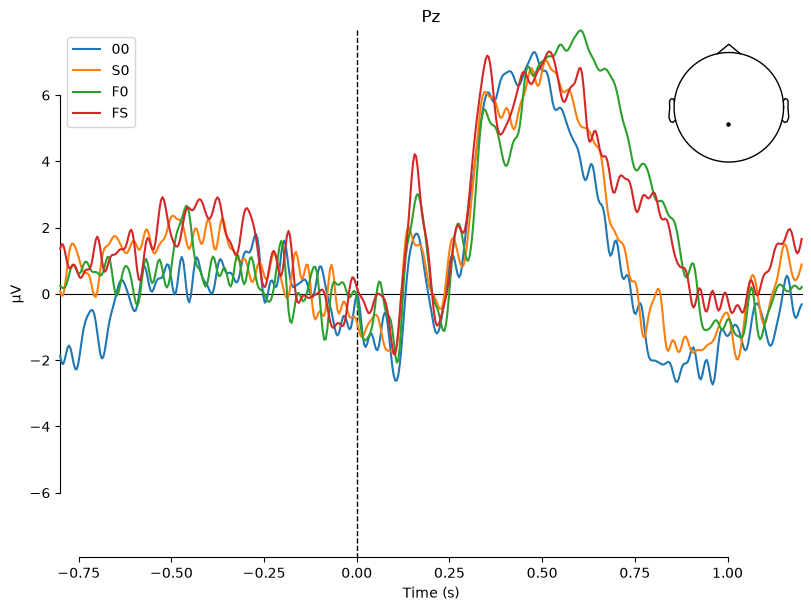

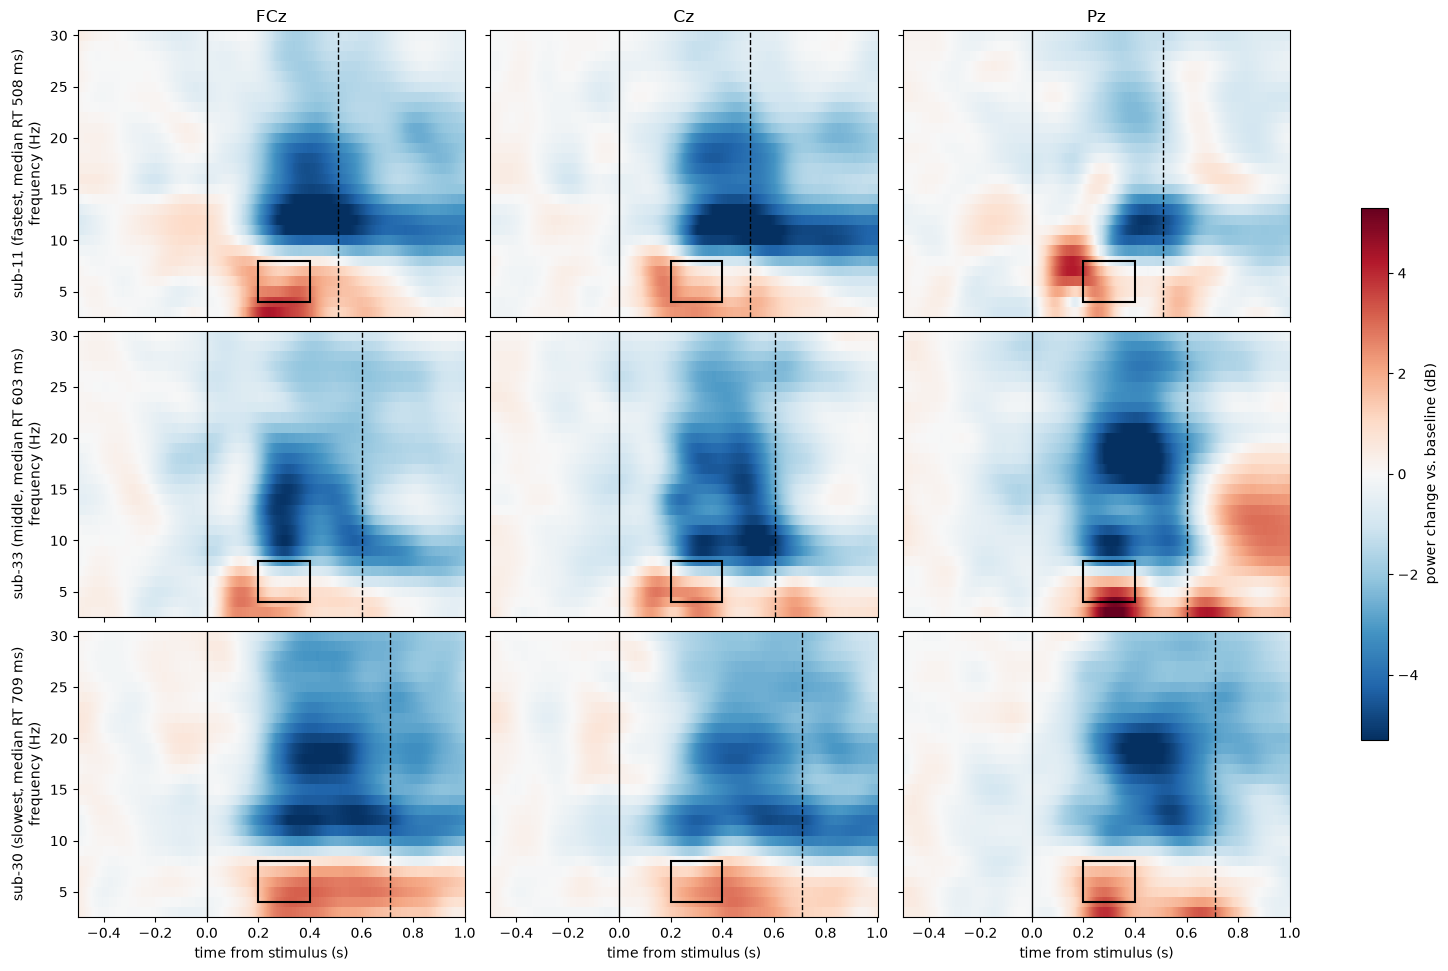

In [30]:
panels = {(s, ch): db(w["all"], ch)[:, tmask] for s, w in wavelet.items() for ch in PANEL_CHANNELS}
vlim = np.percentile(np.abs(np.concatenate([p.ravel() for p in panels.values()])), 99)

fig, axes = plt.subplots(len(wavelet), len(PANEL_CHANNELS), sharex=True, sharey=True, squeeze=False,
                         figsize=(4.4 * len(PANEL_CHANNELS) + 1.2, 3.2 * len(wavelet)), constrained_layout=True)
for i, (subject, w) in enumerate(wavelet.items()):
    median_rt = w["trials"]["rt_s"].median()
    for j, ch in enumerate(PANEL_CHANNELS):
        ax = axes[i, j]
        im = ax.pcolormesh(tfr_times[tmask], FREQS, panels[(subject, ch)], cmap="RdBu_r",
                           vmin=-vlim, vmax=vlim, shading="auto")
        ax.axvline(0, color="k", lw=1)
        ax.axvline(median_rt, color="k", lw=1, ls="--")
        ax.add_patch(Rectangle((SHOW_WINDOW[0], THETA_BAND[0]), SHOW_WINDOW[1] - SHOW_WINDOW[0],
                               THETA_BAND[1] - THETA_BAND[0], fill=False, ec="k", lw=1.5))
        if i == 0:
            ax.set_title(ch)
        if i == len(wavelet) - 1:
            ax.set_xlabel("time from stimulus (s)")
    axes[i, 0].set_ylabel(f"{subject} ({WAVELET_SUBJECTS[subject]}, median RT {median_rt * 1000:.0f} ms)\nfrequency (Hz)")
fig.colorbar(im, ax=axes, shrink=0.6, label="power change vs. baseline (dB)")
fig.savefig(FIG_DIR / "wavelet_tfr_3_subjects.png", dpi=150)
plt.show()

### Figure 2 - Theta time course
Here we look at the averaged 4 different conditions per subject. Dotted lines are that condition's median RT; the grey band is the theta window.

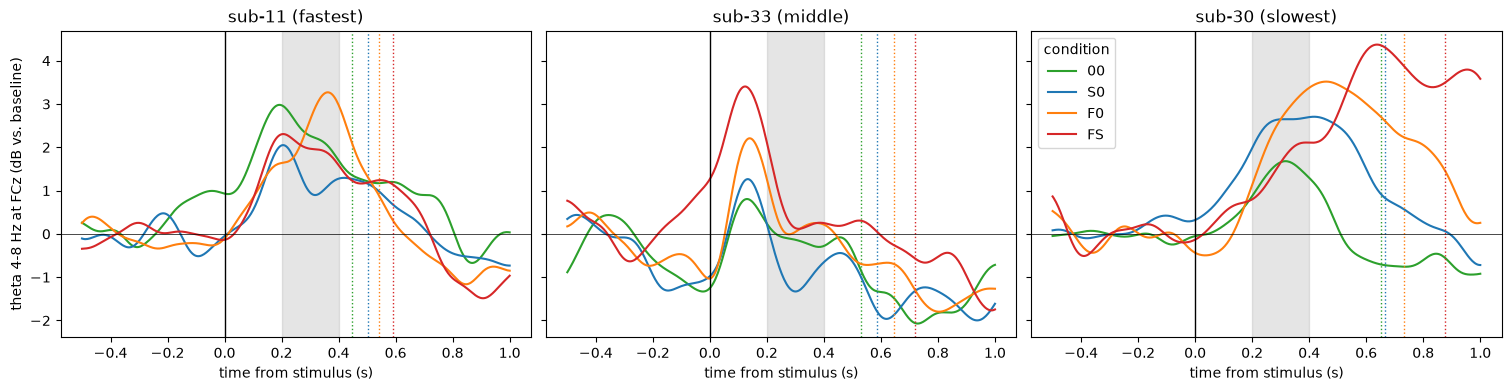

In [31]:
colors = dict(zip(CONDITIONS, ["tab:green", "tab:blue", "tab:orange", "tab:red"]))
fig, axes = plt.subplots(1, len(wavelet), sharey=True, squeeze=False, figsize=(5 * len(wavelet), 3.8),
                         constrained_layout=True)
for ax, (subject, w) in zip(axes[0], wavelet.items()):
    for cond in CONDITIONS:
        ax.plot(tfr_times[tmask], db(w[cond], "FCz")[fmask].mean(axis=0)[tmask], color=colors[cond], label=cond)
        ax.axvline(w["trials"].loc[w["trials"]["condition"] == cond, "rt_s"].median(), color=colors[cond], ls=":", lw=1)
    ax.axvspan(*SHOW_WINDOW, color="gray", alpha=0.2)
    ax.axvline(0, color="k", lw=1)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(f"{subject} ({WAVELET_SUBJECTS[subject]})")
    ax.set_xlabel("time from stimulus (s)")
axes[0, 0].set_ylabel(f"theta {THETA_BAND[0]}-{THETA_BAND[1]} Hz at FCz (dB vs. baseline)")
axes[0, -1].legend(title="condition")
fig.savefig(FIG_DIR / "wavelet_theta_timecourse_3_subjects.png", dpi=150)
plt.show()

In [32]:
rows = []
tm = (tfr_times >= SHOW_WINDOW[0]) & (tfr_times <= SHOW_WINDOW[1])
for subject, w in wavelet.items():
    row = {"subject": subject, "speed": WAVELET_SUBJECTS[subject], "n_trials": len(w["trials"]),
           "median_rt_ms": round(w["trials"]["rt_s"].median() * 1000)}
    for key in ["all"] + CONDITIONS:
        row[f"theta_{key}"] = round(db(w[key], "FCz")[fmask][:, tm].mean(), 2)
    row["FS_minus_00"] = round(row["theta_FS"] - row["theta_00"], 2)
    rows.append(row)
wavelet_summary = pd.DataFrame(rows).set_index("subject")
wavelet_summary.to_csv(FIG_DIR / "wavelet_3_subjects_summary.csv")
wavelet_summary

,speed,n_trials,median_rt_ms,theta_all,theta_00,theta_S0,theta_F0,theta_FS,FS_minus_00
subject,,,,,,,,,
sub-11,fastest,387,508,2.09,2.33,1.33,2.52,2.00,-0.33
sub-33,middle,404,603,-0.06,-0.13,-0.89,0.28,0.55,0.68
sub-30,slowest,400,709,2.02,1.43,2.55,2.50,1.57,0.14


## 18. Channel selection

For every channel we measure the P300 and theta-power with all 4 conditions together, per subject, and averages across subjects.



In [33]:
import json

P300_LOC_WINDOW  = (0.3, 0.6)   #literature values for windows, used to locate the channels
THETA_LOC_WINDOW = (0.2, 0.5)
TOP_N = 5 #seeing the top 5 channels 

#getting 1 P300 value and 1 theta value per channel
def channel_scores(epochs):
    p300 = epochs.copy().crop(*P300_LOC_WINDOW).get_data().mean(axis=(0, 2)) * 1e6
    tfr = morlet_power(epochs, freqs=THETA_FREQS)                      # from section 17
    tm = (tfr.times >= THETA_LOC_WINDOW[0]) & (tfr.times <= THETA_LOC_WINDOW[1])
    theta_db = 10 * tfr.data[:, :, tm].mean(axis=(1, 2))
    return pd.DataFrame({"p300_uv": p300, "theta_db": theta_db}, index=epochs.ch_names)


# score every channel for every subject
scores, skipped = {}, {}
for subject in SUBJECTS:
    cache = SCORE_DIR / f"scores_{subject}.csv"
    if cache.exists():
        scores[subject] = pd.read_csv(cache, index_col=0)
        continue
    try:
        epochs_s, _ = load_epochs(subject)
    except Exception:
        skipped[subject] = "no epochs file yet"
        continue
    if len(epochs_s) == 0:
        skipped[subject] = "0 epochs kept (all trials rejected)"
        continue
    scores[subject] = channel_scores(epochs_s)
    scores[subject].to_csv(cache)
    print(f"{subject}: channels scored")


print(f"Using {len(scores)} subjects: {list(scores)}")
if skipped:
    print("Skipped:", skipped)
assert scores, "No subject has usable epochs yet: run the epoching section first"

#average over all subjects so get 1 value per channel
common = [c for c in next(iter(scores.values())).index if all(c in s.index for s in scores.values())]
group = sum(s.loc[common] for s in scores.values()) / len(scores)

#taking the channels with the highest group-mean values
P300_ROI  = group["p300_uv"].nlargest(TOP_N).index.tolist()
THETA_ROI = group["theta_db"].nlargest(TOP_N).index.tolist()

print(f"{len(scores)} subjects, {len(common)} channels")
print(f"\nP300 top {TOP_N} (uV):\n{group.loc[P300_ROI, 'p300_uv'].round(2).to_string()}")
print(f"\nTheta top {TOP_N} (dB):\n{group.loc[THETA_ROI, 'theta_db'].round(2).to_string()}")
theta_increases = bool(group.loc[THETA_ROI, "theta_db"].max() > 0)
if not theta_increases:
    print("\nNOTE: every theta value is <= 0 dB, so these are the least-negative channels, not a theta increase.")

with open(FEAT_DIR / "selected_channels.json", "w") as f:
    json.dump({"p300_roi": P300_ROI, "theta_roi": THETA_ROI, "top_n": TOP_N,
               "theta_increase_present": theta_increases, "n_subjects": len(scores)}, f, indent=2)

Using 41 subjects: ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-08', 'sub-09', 'sub-10', 'sub-11', 'sub-12', 'sub-13', 'sub-14', 'sub-15', 'sub-17', 'sub-18', 'sub-19', 'sub-20', 'sub-21', 'sub-22', 'sub-23', 'sub-24', 'sub-25', 'sub-26', 'sub-27', 'sub-28', 'sub-29', 'sub-30', 'sub-31', 'sub-32', 'sub-33', 'sub-34', 'sub-35', 'sub-36', 'sub-37', 'sub-38', 'sub-39', 'sub-40', 'sub-41', 'sub-42']
Skipped: {'sub-16': '0 epochs kept (all trials rejected)'}
41 subjects, 124 channels

P300 top 5 (uV):
PPO1h    4.66
PPO2h    4.55
P2       4.41
Pz       4.35
PO3      4.18

Theta top 5 (dB):
FCz      1.24
FCC1h    1.22
C1       1.13
Cz       1.11
FCC2h    1.08


C:\Users\krutv\AppData\Local\Temp\ipykernel_16580\721497703.py:50: RuntimeWarning: epochs._get_data() can't run because this Epochs-object is empty. You might want to check Epochs.drop_log or Epochs.plot_drop_log() to see why epochs were dropped.
  epochs = mne.read_epochs(EPO_DIR / f"{subject}_epo.fif", preload=True, verbose=False)
C:\Users\krutv\AppData\Local\Temp\ipykernel_16580\721497703.py:50: RuntimeWarning: epochs._get_data() can't run because this Epochs-object is empty. You might want to check Epochs.drop_log or Epochs.plot_drop_log() to see why epochs were dropped.
  epochs = mne.read_epochs(EPO_DIR / f"{subject}_epo.fif", preload=True, verbose=False)


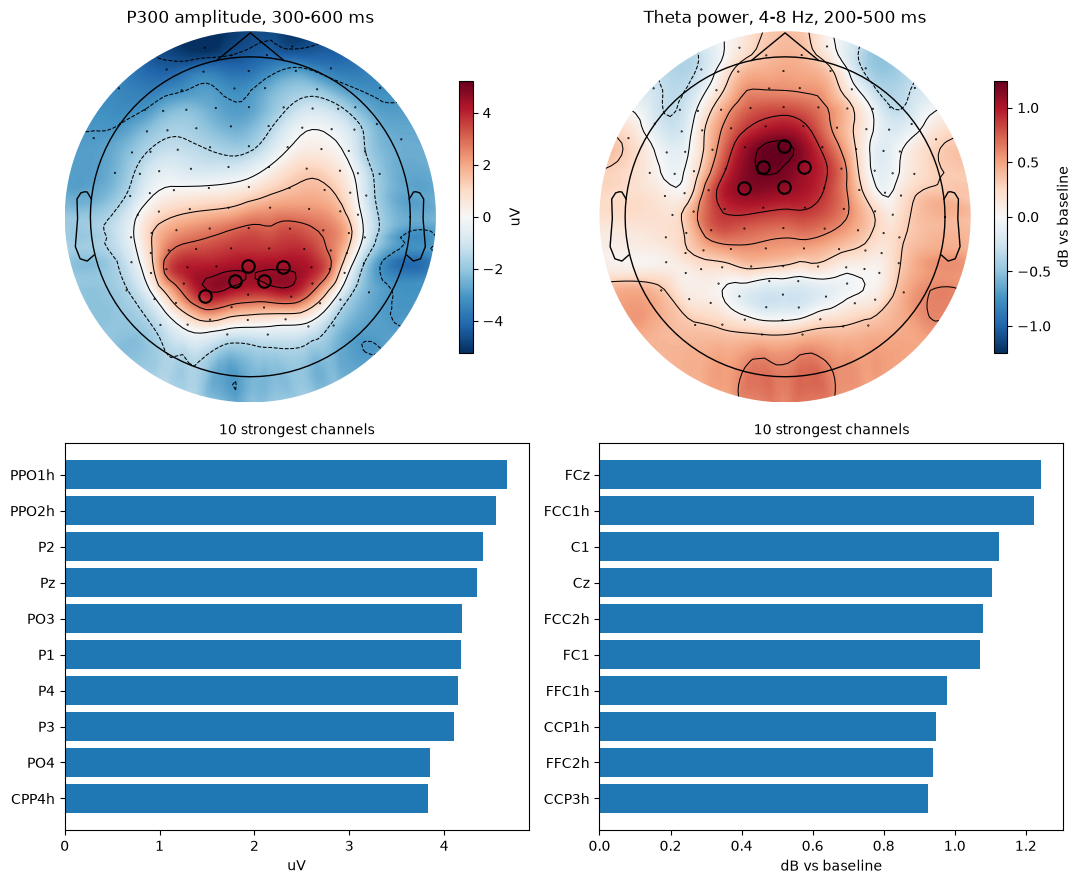

In [34]:
info = mne.create_info(list(group.index), sfreq=250, ch_types="eeg")
info.set_montage(MONTAGE, on_missing="ignore", verbose=False)

panels = [("p300_uv", P300_ROI, "P300 amplitude, 300-600 ms", "uV"),
          ("theta_db", THETA_ROI, "Theta power, 4-8 Hz, 200-500 ms", "dB vs baseline")]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for col, (name, roi, title, unit) in enumerate(panels):
    mask = group.index.isin(roi)
    im, _ = mne.viz.plot_topomap(group[name].values, info, axes=axes[0, col], show=False, mask=mask,
                                 mask_params=dict(marker="o", markerfacecolor="none",
                                                  markeredgecolor="k", markersize=9, markeredgewidth=1.5))
    plt.colorbar(im, ax=axes[0, col], shrink=0.7, label=unit)
    axes[0, col].set_title(f"{title}")

    top = group[name].nlargest(10)[::-1]
    axes[1, col].barh(top.index, top.values)
    axes[1, col].set_xlabel(unit)
    axes[1, col].set_title("10 strongest channels", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "channel_selection.png", dpi=150)
plt.show()